Importing My Dataset and making an(n, x, y, 3) array

In [15]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

IMG_DIR = Path("/Users/abodynasser22/Desktop/D7041E/Lab1/MyDataset")  
EXTS = {".png"}

# Samla bildsökvägar deterministiskt
paths = sorted((p for p in IMG_DIR.rglob("*") if p.suffix.lower() in EXTS),
               key=lambda p: p.as_posix().lower())


n = len(paths)
X = np.empty((n, 28, 28, 3), dtype=np.uint8)

for i, p in enumerate(paths):
    img = Image.open(p).convert("RGB")
    img = img.resize((28, 28), Image.BILINEAR) 
    X[i] = np.asarray(img, dtype=np.uint8)

print("Shape:", X.shape, "| dtype:", X.dtype)  


Shape: (25, 28, 28, 3) | dtype: uint8


PlotSample function

In [16]:
def PlotSample(index, X):
    """Plotta provet X[index] (form: 28x28x3)."""
    plt.figure()
    plt.imshow(X[index])
    plt.axis("off")
    plt.show()

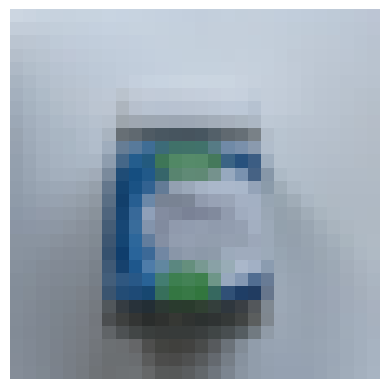

In [17]:
# Endast bilder
PlotSample(2, X)


Dimensioillity reduction

In [18]:
n, h, w, c = X.shape          # t.ex. (n, 28, 28, 3)
X2D = X.reshape(n, h*w*c)
print(X2D.shape)

(25, 2352)


Rescaling by dividing to 255

In [19]:
X_norm = X2D / 255.
print ('X.min()', X_norm.min())
print ('X.max()', X_norm.max())

X.min() 0.0196078431372549
X.max() 0.9607843137254902


Mean Subtraction

In [20]:
X_norm.mean(axis=0).shape

(2352,)

In [21]:
X_norm.mean(axis=0)

array([0.76533333, 0.80407843, 0.84360784, ..., 0.63121569, 0.66368627,
       0.69066667])

In [22]:
X_norm = X_norm - X_norm.mean(axis=0)
X_norm.mean(axis=0)

array([-3.10862447e-16, -2.88657986e-16, -2.26485497e-16, ...,
        2.79776202e-16,  2.66453526e-17,  2.22044605e-18])

Calculate the Covariance Matrix


In [23]:
cov = np.cov(X_norm, rowvar=False)

In [24]:
cov.shape

(2352, 2352)

Singular Value Decomposition (SVD)

In [25]:
U,S,V = np.linalg.svd(cov)

Apply ZCA Whitening Transformation


In [26]:
epsilon = 0.1e-19
X_ZCA = U.dot(np.diag(1.0/np.sqrt(S + epsilon))).dot(U.T).dot(X_norm.T).T



Final Rescaling

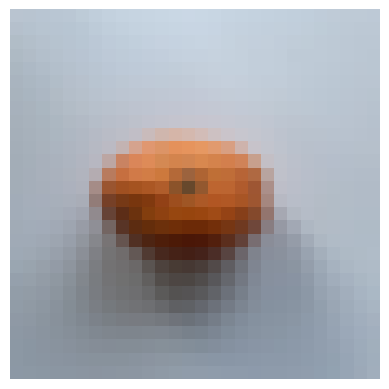

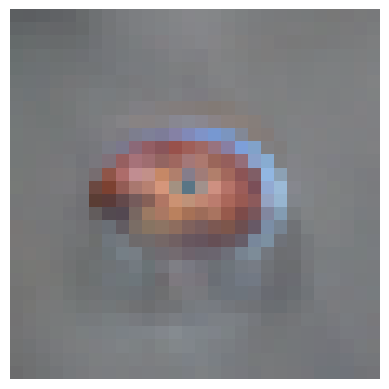

In [28]:
X_ZCA_rescaled = (X_ZCA - X_ZCA.min()) / (X_ZCA.max() - X_ZCA.min())
PlotSample(3, X)
PlotSample(3, X_ZCA_rescaled.reshape(n, h, w, c))